# Oil Well Development Region Selection — Reserve Prediction, Profitability, and Risk Assessment

# 1. Business Context and Objectives

The fictional oil exploration company OilyGiant plans to invest in developing 200 new oil wells in one of three available regions. To support this decision, the company has provided three synthetic datasets, each containing approximately 100,000 observations of potential well locations, their geological characteristics, and corresponding oil reserves.

The primary objective is to identify the region offering the **highest estimated mean profit**, subject to an estimated probability of financial loss **below 2.5%**.

The company specifies an exploration scenario in which 500 candidate locations are evaluated and the 200 locations with the highest predicted reserves are selected for development. The investment budget is US$100 million, with estimated revenue of US$4.50 per barrel of oil.

## 1.1 Modeling Objective

Develop a separate linear regression model for each region to estimate the oil reserves at a prospective well location from its available geological features.

These predictions will be used to identify promising locations for development. The effectiveness of this strategy will be evaluated on validation data, where the recorded oil reserves are known.

In addition to assessing predictive performance, the project evaluates whether selecting wells according to the models' predictions would lead to profitable investments.

## 1.2 Available Data

The project uses three synthetic geological exploration datasets, each containing 100,000 observations. Each observation represents a potential oil-well location, identified by `id`, with features `f0`, `f1`, and `f2` (geological characteristics whose physical meanings are not specified), and `product` (oil reserves in thousands of barrels).

Datasets:
- `geo_data_0.csv`
- `geo_data_1.csv`
- `geo_data_2.csv`

Columns:
- `id` — identifier of a potential well location
- `f0`, `f1`, `f2` — geological features with unspecified physical meanings
- `product` — oil reserve volume, in **thousands of barrels**

## 1.3 Scenario Assumptions and Limitations

- The requirement to evaluate **500 candidate locations** is a stipulated operating assumption. The data do not explain why this number was chosen or provide the cost of investigating each location.
- The datasets are synthetic and contain no detailed information about well-specific drilling costs, operating conditions, contracts, or external factors that could affect profitability.

Consequently, the results should be understood as an evaluation of a well-selection strategy under the stated assumptions, not as a definitive forecast of a real-world drilling operation's financial performance.

## 1.4 Analytical Strategy

1. **Data preparation:** assess data integrity and prepare variables for modeling.
2. **Training and validation:** build a linear regression model for each region using a 75% training / 25% validation split. Assess prediction accuracy using RMSE.
3. **Preliminary profitability analysis:** select the 200 wells with the highest predicted reserves from the entire validation set for each region, then calculate profit using the recorded reserves. This compares a particular selection, but does not fully represent the stipulated operating scenario.
4. **Selection-strategy simulation:** use bootstrap resampling to generate 1,000 samples of 500 candidate locations per region; in each, select the top 200 wells according to the respective model's predictions.
5. **Financial evaluation:** estimate the distribution of simulated profits, mean profit, variability, and loss probability for each region.
6. **Recommendation:** identify the region with the highest estimated mean profit among those satisfying the 2.5% loss-risk threshold, under the assumption that the trained models will be used to select future wells.

### OilyGiant's Requirements

- Only linear regression models may be used.
- An exploration survey evaluates 500 candidate locations; the 200 most promising are selected for the profit calculation.
- The budget for developing 200 wells is US$100 million.
- Each barrel of crude oil generates US$4.50 in revenue. One unit of `product` represents 1,000 barrels and therefore generates US$4,500.
- The maximum acceptable estimated probability of loss is **strictly below 2.5%**.
- Among qualifying regions, select the one with the highest mean simulated profit.

The datasets are synthetic and do not provide individual well characteristics beyond the supplied features or contractual details.

## 1.5 Evaluation Metrics

| Metric | Purpose |
|---|---|
| RMSE (thousand barrels) | Evaluate prediction accuracy |
| Mean oil reserves (thousand barrels) | Summarize each region's reserve potential |
| Mean simulated profit (US$) | Compare simulated financial outcomes across regions |
| Central 95% range of simulated profits | Characterize variability in simulated financial outcomes |
| Estimated probability of loss (%) | Evaluate investment risk under the simulated strategy |
| Monte Carlo standard error (percentage points) | Quantify simulation-related uncertainty in the estimated loss probability |

# 2. Data Exploration and Preparation

The notebook searches for the three CSV files in `../data/` or `../datasets/` relative to the notebook's working directory, and alternatively in `/datasets/` (used in the original environment). All three files must be present in the selected directory.

In [1]:
# Import libraries
from pathlib import Path

import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

from matplotlib import pyplot as plt

from IPython.display import display


In [2]:
filenames = [f"geo_data_{i}.csv" for i in range(3)]

# Load datasets
data_dir = next(
    (
        path for path in [Path("../data"), Path("../datasets"), Path("/datasets/")] if all((path /
        filename).is_file() for filename in filenames)
    ),
    None,
)

if data_dir is None:
    raise FileNotFoundError("The files were not found. Place geo_data_0.csv, geo_data_1.csv, and geo_data_2.csv in ../data/, ../datasets/, or /datasets/.")


geo_data_0 = pd.read_csv(data_dir / "geo_data_0.csv")
geo_data_1 = pd.read_csv(data_dir / "geo_data_1.csv")
geo_data_2 = pd.read_csv(data_dir / "geo_data_2.csv")
region_datasets = {0: geo_data_0, 1: geo_data_1, 2: geo_data_2}

In [3]:
data_quality = pd.DataFrame(
    [
        {
            "Region": f"Region {region}",
            "Observations": len(df),
            "Missing values": int(df.isna().sum().sum()),
            "Duplicate rows": int(df.duplicated().sum()),
            "Repeated IDs": int(df["id"].duplicated().sum()),
            "Mean reserves (thousand barrels)": df["product"].mean(),
        }
        for region, df in region_datasets.items()
    ]
)
print("Data quality by region:")
display(data_quality.round(2))

Data quality by region:


,Region,Observations,Missing values,Duplicate rows,Repeated IDs,Mean reserves (thousand barrels)
0,Region 0,100000,0,0,10,92.50
1,Region 1,100000,0,0,4,68.83
2,Region 2,100000,0,0,4,95.00


In [4]:
for region, df in region_datasets.items():
    print(f"\nRepeated IDs in Region {region}:")
    print(df.loc[df["id"].duplicated(keep=False)].sort_values(by="id"))


Repeated IDs in Region 0:
          id        f0        f1         f2     product
66136  74z30  1.084962 -0.312358   6.990771  127.643327
64022  74z30  0.741456  0.459229   5.153109  140.771492
51970  A5aEY -0.180335  0.935548  -2.094773   33.020205
3389   A5aEY -0.039949  0.156872   0.209861   89.249364
69163  AGS9W -0.933795  0.116194  -3.655896   19.230453
42529  AGS9W  1.454747 -0.479651   0.683380  126.370504
931    HZww2  0.755284  0.368511   1.863211   30.681774
7530   HZww2  1.061194 -0.373969  10.430210  158.828695
63593  QcMuo  0.635635 -0.473422   0.862670   64.578675
1949   QcMuo  0.506563 -0.323775  -2.215583   75.496502
75715  Tdehs  0.112079  0.430296   3.218993   60.964018
21426  Tdehs  0.829407  0.298807  -0.049563   96.035308
92341  TtcGQ  0.110711  1.022689   0.911381  101.318008
60140  TtcGQ  0.569276 -0.104876   6.440215   85.350186
89582  bsk9y  0.398908 -0.400253  10.122376  163.433078
97785  bsk9y  0.378429  0.005837   0.160827  160.637302
41724  bxg6G -0.82375

**Data quality assessment.** There are no missing values or fully duplicated rows. However, there are **10 repeated IDs in Region 0 and 4 in each of Regions 1 and 2**. Records sharing these IDs have different features, so they are retained. In a real application, the data provider would need to confirm whether they represent different wells or identification errors. For this analysis, records with repeated IDs are retained as distinct observations; the cause of the repetitions cannot be established from the available data.

The `id` field will not be used as a predictive feature. Actual values and model predictions remain aligned through the **row index**.

# 3. Training and Evaluating a Linear Regression Model for Each Region

Each region has its own **linear regression** model. Observations are randomly divided into **75% training and 25% validation**, using a fixed random seed for reproducibility.

`StandardScaler` runs inside a `Pipeline`: its scaling parameters are fitted **only on training data**, preventing leakage from the validation set. Although scaling is not required for ordinary unregularized linear regression, it demonstrates a safe and reusable preprocessing workflow.

The evaluation metric is **root mean squared error (RMSE)**, expressed in the same units as the target: thousands of barrels.

## Helper Functions

In [5]:
def features_target_split(
    data_df: pd.DataFrame, non_training_columns: list[str], target_column: str
) -> tuple[pd.DataFrame, pd.Series]:
    """Split a DataFrame into features and target."""
    features = data_df.drop(columns=non_training_columns + [target_column], axis=1)
    target = data_df.loc[:, target_column]
    return features, target


def model_pipe(num_columns: list[str]):
    ''' Create a preprocessing and linear regression pipeline.'''

    scaler = StandardScaler()

    preprocessor = ColumnTransformer(
        transformers=[("num_preprocess", scaler, num_columns)],
        remainder="passthrough"
    )

    pipe = Pipeline([
        ("column_transform", preprocessor),
        ("model", LinearRegression())
    ])

    return pipe



def region_workflow(
    data_df: pd.DataFrame,
    non_training_columns: list[str],
    feature_columns: list[str],
    target_column: str,
    test_size: float,
    random_state: int,
) -> tuple[pd.Series, pd.Series, pd.DataFrame, float, float, Pipeline]:
    """Train and validate a model while preserving prediction indices and IDs."""

    features, target = features_target_split(
        data_df, non_training_columns, target_column
    )

    features_train, features_valid, target_train, target_valid = train_test_split(
        features, target, test_size=test_size, random_state=random_state
    )

    pipe = model_pipe(feature_columns)
    pipe.fit(features_train, target_train)

    predicted_valid = pd.Series(pipe.predict(features_valid), index=target_valid.index)

    validation_results = pd.DataFrame(
        {"actual_product": target_valid,
         "predicted_product": predicted_valid}
        ).merge(
            data_df[non_training_columns],
            how="left",
            left_index=True,
            right_index=True
        )

    mean_predicted = predicted_valid.mean()
    root_mean_square_error = mean_squared_error(target_valid, predicted_valid) ** (1/2)

    return (
        target_valid,
        predicted_valid,
        validation_results,
        mean_predicted,
        root_mean_square_error,
        pipe,
    )

## Training and Validation

In [6]:
# Workflow parameters
split_state = 12345 # random seed for train_test_split
valid_size = 0.25
non_training_columns = ["id"]
feature_columns = ["f0","f1","f2"]
target_column = "product"

# Region 0
(
    target_valid_0, predicted_valid_0, validation_results_0,
    mean_predicted_0, rmse_0, pipe_0,
) = region_workflow(
    geo_data_0, non_training_columns, feature_columns,
    target_column, valid_size, split_state,
)

# Region 1
(
    target_valid_1, predicted_valid_1, validation_results_1,
    mean_predicted_1, rmse_1, pipe_1,
) = region_workflow(
    geo_data_1, non_training_columns, feature_columns,
    target_column, valid_size, split_state,
)

# Region 2
(
    target_valid_2, predicted_valid_2, validation_results_2,
    mean_predicted_2, rmse_2, pipe_2,
) = region_workflow(
    geo_data_2, non_training_columns, feature_columns,
    target_column, valid_size, split_state,
)

# Validation results by region
validation_by_region = {
    0: validation_results_0,
    1: validation_results_1,
    2: validation_results_2,
}

In [7]:
model_summary = pd.DataFrame(
    {
        "Region": ["Region 0", "Region 1", "Region 2"],
        "Mean predicted reserves (thousand barrels)": [
            mean_predicted_0, mean_predicted_1, mean_predicted_2
        ],
        "Validation RMSE (thousand barrels)": [rmse_0, rmse_1, rmse_2],
    }
)
display(model_summary.round(2))

,Region,Mean predicted reserves (thousand barrels),Validation RMSE (thousand barrels)
0,Region 0,92.59,37.58
1,Region 1,68.73,0.89
2,Region 2,94.97,40.03


## Interpretation

Regions 0 and 2 have higher mean predicted reserves, but their prediction errors are substantially larger. Region 1 has the lowest mean predicted reserves (**68.73 thousand barrels**) and the lowest RMSE (**0.89 thousand barrels**). This indicates greater predictive accuracy on the validation data, **not a guarantee of future performance**.

These metrics alone do not resolve the business problem: we must select wells using the models' predictions and evaluate the financial outcomes and risks of those selections. Careful assessment is particularly important because the specified strategy examines only 500 candidate locations and develops 200 wells.

# 4. Exploratory Profitability Analysis

## 4.1 Financial Assumptions and Break-Even Point

Estimated revenue depends on the recorded reserves of the selected wells. Profit is calculated as:

$\text{Profit} = (\text{Recorded reserves in thousands of barrels} \times 4{,}500) - 100{,}000{,}000$

In [8]:
# Number of wells to develop
oil_well_num = 200
# Development budget: US$100 million
budget = 100_000_000
# Revenue per unit of product (1,000 barrels).
product_unit_rev = 4500
# Maximum acceptable probability of loss (as a proportion).
loss_risk_max = 0.025


# With a US$100 million budget for 200 wells, each well must generate, on
# average, at least US$500,000 in revenue to break even (about 111.11 units).
product_mean_min = budget / oil_well_num / product_unit_rev
print(f"Break-even reserves per well: {product_mean_min:.2f} thousand barrels")

Break-even reserves per well: 111.11 thousand barrels


To recover the US$100 million investment across 200 wells, average production would need to reach **111.11 thousand barrels per well**, under the project's simplified price and cost assumptions.

In [9]:
display(
    data_quality[["Region", "Mean reserves (thousand barrels)"]].round(2)
)

,Region,Mean reserves (thousand barrels)
0,Region 0,92.50
1,Region 1,68.83
2,Region 2,95.00


None of the three regions has an overall mean reserve volume above the break-even requirement. This does not mean that none of the regions can be profitable: the company intends to select the most promising wells rather than develop locations at random. The regional mean reserves, whether recorded or predicted, are below the required average for an unselective 200-well investment.

# 5. Preliminary Profitability Analysis of the Top 200 Selected Wells

For each region, validation observations are ranked by **predicted reserves**, and the top 200 are selected. Profit is calculated using their corresponding **recorded reserves**, allowing us to compare model-driven selections against the known outcomes in the dataset.

The procedure for each region is to:
- Select the top 200 wells by predicted reserves.
- Sum the corresponding recorded reserve volumes.
- Calculate revenue from those volumes.
- Subtract the development budget to obtain estimated profit.

Because the selection uses approximately 25,000 validation observations, it considers far more candidates than the 500 allowed under the stipulated operating scenario. These results describe one particular selection and **do not represent the expected profit of the company's specified selection strategy**.

### Helper Function

The following function selects the 200 highest-ranked wells according to predicted reserves, sums their recorded reserves, and calculates revenue and profit.

It returns the selected wells, estimated revenue, and estimated profit.

In [10]:
def region_predicted_revenue_profit(
    region_data: pd.DataFrame,
    sort_column: str,
    target_column: str,
    count: int,
    budget: int,
    product_unit_rev,
) -> tuple[pd.DataFrame, float, float]:
    """Select wells by predicted reserves, then calculate revenue and profit from recorded reserves."""

    top_wells = region_data.sort_values(
        by=sort_column,
        ascending=False
        ).head(count)

    target_product_sum = top_wells[target_column].sum()

    potential_revenue = target_product_sum * product_unit_rev

    profit = potential_revenue - budget

    return top_wells, potential_revenue, profit


In [11]:
top_wells_0, potential_revenue_0, profit_0 = region_predicted_revenue_profit(
    validation_results_0,
    "predicted_product",
    "actual_product",
    oil_well_num,
    budget,
    product_unit_rev,
)
top_wells_1, potential_revenue_1, profit_1 = region_predicted_revenue_profit(
    validation_results_1,
    "predicted_product",
    "actual_product",
    oil_well_num,
    budget,
    product_unit_rev,
)
top_wells_2, potential_revenue_2, profit_2 = region_predicted_revenue_profit(
    validation_results_2,
    "predicted_product",
    "actual_product",
    oil_well_num,
    budget,
    product_unit_rev,
)

top_wells_summary = pd.DataFrame(
    {
        "Region": ["Region 0", "Region 1", "Region 2"],
        "Revenue (US$ million)": [
            potential_revenue_0, potential_revenue_1, potential_revenue_2
        ],
        "Profit (US$ million)": [profit_0, profit_1, profit_2],
    }
)
top_wells_summary.iloc[:, 1:] /= 1_000_000
display(top_wells_summary.round(2))

,Region,Revenue (US$ million),Profit (US$ million)
0,Region 0,133.21,33.21
1,Region 1,124.15,24.15
2,Region 2,127.10,27.10


**Preliminary finding.** Region 0 generates the highest observed profit in this specific top-200 selection (**US$33.21 million**). However, this result comes from a single selection using the full validation set. It does not measure how profits might vary if a different group of 500 candidates were evaluated.

To compare investment alternatives consistently with the risk constraint, we need to simulate different candidate samples.

# 6. Profit and Financial Loss Risk Simulation: Bootstrapping

For each region, the **bootstrap** procedure is as follows:

1. Draw **500 observations with replacement** from the validation results.
2. Select the **200 observations with the highest predicted reserves** in that sample.
3. Calculate revenue using the selected observations' **recorded reserves** and subtract the development budget.
4. Repeat **1,000 times** to obtain an empirical distribution of simulated profits.
5. Calculate mean profit, the 2.5th and 97.5th percentiles, and the fraction of simulations with negative profit.

**Statistical interpretation:**

- The percentiles bound the central 95% of **simulated profit outcomes**. They should not automatically be interpreted as a 95% confidence interval for **mean** profit.
- The risk estimate is conditional on the data, fitted models, and simulation assumptions.
- Resampling with replacement reflects the assumption that future well locations may have geological features and reserve volumes drawn from a distribution similar to the available data. The simulation thus estimates the performance of applying the trained models to new candidate sets, with the models and financial assumptions held fixed.

In [12]:
# Central 95% of simulated profits (2.5% in each tail)
profit_quantiles = (0.025,0.975)

bootstrap_sample_size = 500
bootstrap_samples = 1000

## Helper Function

In [13]:
def profit_distribution(
    region_data: pd.DataFrame,
    sort_column: str,
    target_column: str,
    bootstrap_samples: int,
    bootstrap_sample_size: int,
    top_well_num: int,
    profit_quantiles: tuple[float, float],
    budget: float,
    product_unit_rev: float,
    random_state: int = 12345
) -> tuple[float,float,float,float,pd.Series]:
    """Simulate 500-to-200 well selections and calculate mean profit, the central 95% profit range, and estimated loss probability."""

    bootstrap_state = np.random.RandomState(random_state)
    profits = []

    for _ in range(bootstrap_samples):

        subsample = region_data.sample(
            n=bootstrap_sample_size, replace=True, random_state=bootstrap_state
        )

        sorted_subsample = subsample.sort_values(
            by=sort_column,
            ascending=False
        )

        top_subsample = sorted_subsample.head(top_well_num)
        total_revenue = top_subsample[target_column].sum() * product_unit_rev
        profits.append(total_revenue - budget)

    profits = pd.Series(profits)
    lower = profits.quantile(profit_quantiles[0])
    upper = profits.quantile(profit_quantiles[1])
    profit_mean = profits.mean()
    loss_proba = (profits < 0).mean()

    return profit_mean, lower, upper, loss_proba, profits


In [14]:
profit_mean_0, lower_0, upper_0, loss_proba_0, profits_0 = profit_distribution(
    validation_results_0, "predicted_product", "actual_product",
    bootstrap_samples, bootstrap_sample_size, oil_well_num,
    profit_quantiles, budget, product_unit_rev,
)
profit_mean_1, lower_1, upper_1, loss_proba_1, profits_1 = profit_distribution(
    validation_results_1, "predicted_product", "actual_product",
    bootstrap_samples, bootstrap_sample_size, oil_well_num,
    profit_quantiles, budget, product_unit_rev,
)
profit_mean_2, lower_2, upper_2, loss_proba_2, profits_2 = profit_distribution(
    validation_results_2, "predicted_product", "actual_product",
    bootstrap_samples, bootstrap_sample_size, oil_well_num,
    profit_quantiles, budget, product_unit_rev,
)

In [15]:
bootstrap_summary = pd.DataFrame(
    {
        "Region": ["Region 0", "Region 1", "Region 2"],
        "Mean profit (US$ million)": [
            profit_mean_0, profit_mean_1, profit_mean_2
        ],
        "Lower 2.5% quantile (US$ million)": [lower_0, lower_1, lower_2],
        "Upper 97.5% quantile (US$ million)": [upper_0, upper_1, upper_2],
        "Estimated loss risk (%)": [
            100 * loss_proba_0, 100 * loss_proba_1, 100 * loss_proba_2
        ],
        "Meets risk threshold": [
            "Yes" if risk < loss_risk_max else "No"
            for risk in (loss_proba_0, loss_proba_1, loss_proba_2)
        ],
        "Monte Carlo standard error (pp)": [
        100 * np.sqrt(p * (1 - p) / len(profits))
        for p, profits in zip(
            [loss_proba_0, loss_proba_1, loss_proba_2],
            [profits_0, profits_1, profits_2]
        )
        ]
    }
)
bootstrap_summary.iloc[:, 1:4] /= 1_000_000
display(bootstrap_summary.round(4))

,Region,Mean profit (US$ million),Lower 2.5% quantile (US$ million),Upper 97.5% quantile (US$ million),Estimated loss risk (%),Meets risk threshold,Monte Carlo standard error (pp)
0,Region 0,3.9616,-1.1122,9.0977,6.9,No,0.8015
1,Region 1,4.5605,0.3382,8.5229,1.5,Yes,0.3844
2,Region 2,4.0440,-1.6335,9.5036,7.6,No,0.8380


### Profitability and Risk Visualizations

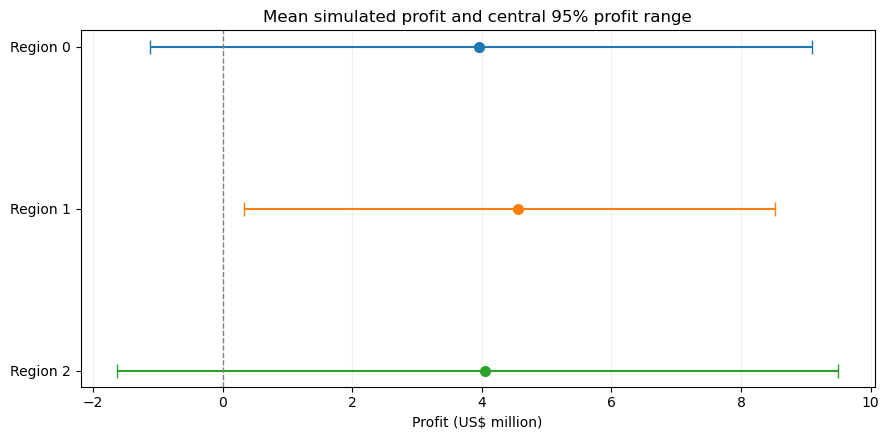

In [16]:
figures_dir = Path("../assets/figures/")
figures_dir.mkdir(exist_ok=True,parents=True)

fig, ax = plt.subplots(figsize=(9, 4.5))

for index, row in bootstrap_summary.iterrows():
    mean = row["Mean profit (US$ million)"]
    lower = row["Lower 2.5% quantile (US$ million)"]
    upper = row["Upper 97.5% quantile (US$ million)"]
    ax.errorbar(
        mean, index,
        xerr=[[mean - lower], [upper - mean]],
        fmt="o", capsize=5, markersize=7,
    )

ax.axvline(0, color="gray", linestyle="--", linewidth=1)
ax.set_yticks(range(len(bootstrap_summary)))
ax.set_yticklabels(bootstrap_summary["Region"])
ax.invert_yaxis()
ax.set_xlabel("Profit (US$ million)")
ax.set_title("Mean simulated profit and central 95% profit range")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(figures_dir / "profit_intervals.png", dpi=160, bbox_inches="tight")
plt.show()

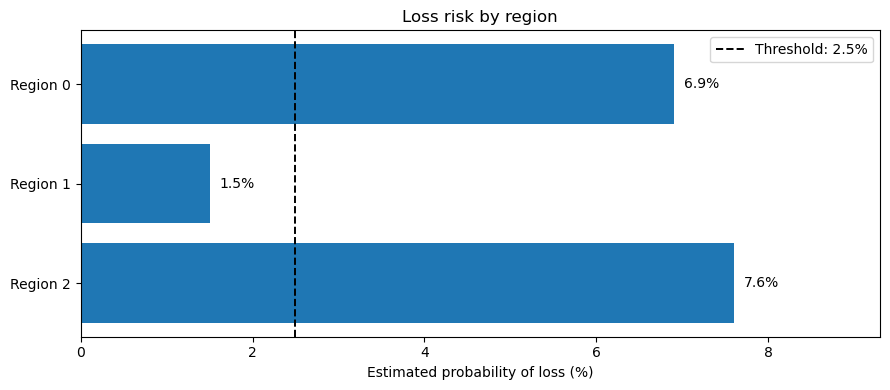

In [17]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(bootstrap_summary["Region"], bootstrap_summary["Estimated loss risk (%)"])
ax.axvline(
    loss_risk_max * 100, color="black", linestyle="--", linewidth=1.4,
    label="Threshold: 2.5%",
)
for i, risk in enumerate(bootstrap_summary["Estimated loss risk (%)"]):
    ax.text(risk + 0.12, i, f"{risk:.1f}%", va="center")
ax.set_xlim(0, max(bootstrap_summary["Estimated loss risk (%)"]) + 1.7)
ax.set_xlabel("Estimated probability of loss (%)")
ax.set_title("Loss risk by region")
ax.invert_yaxis()
ax.legend()
fig.tight_layout()
fig.savefig(figures_dir / "loss_risk.png", dpi=160, bbox_inches="tight")
plt.show()

The first chart compares the mean profit and the central 95% range of simulated profits. The second highlights the **2.5%** maximum acceptable estimated probability of loss. Both figures are also saved to `assets/figures/`.

# 7. Conclusion and Recommendation

Three linear regression models, one for each region, were developed and validated to estimate oil reserves at potential well locations and use these predictions to inform development decisions.

In the initial exploratory analysis, **Region 0 had the highest observed profit, at US$33.21 million**, when the 200 highest-ranked wells were selected from approximately 25,000 available validation locations. However, this selection does not reflect OilyGiant's operating scenario, which evaluates only 500 candidate locations before selecting 200 wells.

To evaluate the strategy under the specified conditions, **1,000 bootstrap simulations per region** were performed. Each simulation sampled 500 observations with replacement and selected the 200 with the highest reserves predicted by the corresponding model. Profits were calculated using reserve volumes recorded in the dataset.

## 7.1 Analysis Results

The simulated selection strategy produced the following results:

| Region | Mean simulated profit | Estimated probability of loss |
|---|---:|---:|
| Region 0 | US$3.96 million | 6.9% |
| **Region 1** | **US$4.56 million** | **1.5%** |
| Region 2 | US$4.04 million | 7.6% |

Region 1 achieved the highest mean simulated profit and lowest estimated probability of loss. It was also the **only region** to satisfy OilyGiant's requirement that the loss probability be below 2.5%.

The model for Region 1 also had the best predictive performance on the validation set, with an RMSE of approximately 0.89 thousand barrels, substantially lower than those of the other regions.

## 7.2 Recommendation

**Region 1 is recommended for new oil-well development, using the selection strategy based on predictions from the linear regression model trained for that region.**

This recommendation reflects the models' ability to guide financially favorable development decisions, not merely the reserve volumes available in each region.

Although Region 0 generated the highest profit in the preliminary analysis, that outcome was obtained from one selection among approximately 25,000 candidates. Across repeated samples of 500 candidates, the strategy based on Region 0's model produced a higher estimated loss risk and lower mean simulated profit than the corresponding strategy in Region 1.

Thus, the recommendation does not necessarily imply that Region 1 has the largest reserves or the most profitable individual wells. Rather, **the model-driven selection strategy for Region 1 offered the best combination of estimated mean profitability and financial risk among the evaluated alternatives**.

## 7.3 Interpretation and Scope of the Recommendation

The results indicate that Region 1 is the most favorable alternative **for the investment and well-selection strategy evaluated in this project**.

This conclusion depends on the assumption that future candidate locations have distributions of geological features and oil reserves similar to those in the available data, and that the financial assumptions remain applicable.

The estimated probabilities of loss are conditional on synthetic data, the fitted models, and the chosen resampling procedure. They should not be interpreted as exact probabilities of financial loss in real operations.

Overall, the project demonstrates the importance of evaluating predictive models not only by prediction accuracy, but also by the financial consequences of decisions made using their predictions.

# 8. Limitations and Next Steps

- **Synthetic data and fixed assumptions:** the analysis does not model changes in oil prices, operating costs, contracts, or physical development constraints.
- **Generalization:** the estimates depend on the representativeness of the observations and stability of the relationships between geological features and reserves.
- **Sampling with replacement:** a bootstrap sample may contain the same observation multiple times; this is a statistical resampling procedure, not a literal drilling plan for 200 distinct physical wells.
- **Approximate probabilities:** loss risk is estimated from 1,000 simulations, so the estimate has sampling uncertainty and should not be interpreted as an exact probability.
- **Identifiers:** repeated IDs should be clarified before real-world operational use.

In a real implementation, next steps would include validating identifier integrity, incorporating varying prices and well-specific costs, testing model robustness on new data, and revisiting the sampling strategy in light of operational constraints.